# Lab 13: Decision Trees in Python
#### **Artificial Intelligence | Section AI 3-1**

#### **Student Name:** Muhammad Salman  
#### **SAP :** 72373  





## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate and Load the Datasets



In [2]:
DATA_DIRS = [Path("data"), Path(".")]

def find_csv(possible_names):
    for folder in DATA_DIRS:
        for name in possible_names:
            candidate = folder / name
            if candidate.exists():
                return candidate
    raise FileNotFoundError(
        "Could not find any of these files: "
        + ", ".join(possible_names)
        + ". Place the downloaded CSV beside this notebook or in ./data/"
    )

heart_path = find_csv(["heart.csv", "Heart.csv"])
telco_path = find_csv([
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "telco_customer_churn.csv"
])
mushroom_path = find_csv(["mushrooms.csv", "mushroom.csv"])

heart_df = pd.read_csv(heart_path)
telco_df = pd.read_csv(telco_path)
mushroom_df = pd.read_csv(mushroom_path)

print("Heart dataset:", heart_df.shape)
print("Telco dataset:", telco_df.shape)
print("Mushroom dataset:", mushroom_df.shape)

Heart dataset: (918, 12)
Telco dataset: (7043, 21)
Mushroom dataset: (8124, 23)


## 3. Reusable Functions for Decision Tree Classification



In [3]:
def prepare_data(df, target_column, drop_columns=None):
    data = df.copy()
    data.columns = data.columns.str.strip()

    if target_column not in data.columns:
        raise ValueError(
            f"Target '{target_column}' not found. Available columns: {list(data.columns)}"
        )

    # Remove rows where the target is missing.
    data = data.dropna(subset=[target_column])

    # Remove identifier columns when specified (for example, customerID).
    if drop_columns:
        data = data.drop(columns=drop_columns, errors="ignore")

    X = data.drop(columns=[target_column]).copy()
    y = data[target_column].copy()

    # Treat blank strings as missing values.
    for column in X.select_dtypes(include=["object", "string"]).columns:
        X[column] = X[column].replace(r"^\\s*$", np.nan, regex=True)

    # Convert columns that should be numeric but may contain blank text.
    for column in X.columns:
        if X[column].dtype == "object":
            converted = pd.to_numeric(X[column], errors="coerce")
            if converted.notna().sum() > 0 and converted.notna().sum() >= 0.8 * X[column].notna().sum():
                X[column] = converted

    # Remove columns that contain no usable values.
    X = X.dropna(axis=1, how="all")

    return X, y


def make_model(X, max_depth=5, criterion="gini"):
    numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_features = [c for c in X.columns if c not in numeric_features]

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = []
    if numeric_features:
        transformers.append(("numeric", numeric_pipeline, numeric_features))
    if categorical_features:
        transformers.append(("categorical", categorical_pipeline, categorical_features))

    preprocessing = ColumnTransformer(transformers=transformers)

    model = Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("classifier", DecisionTreeClassifier(
            max_depth=max_depth,
            criterion=criterion,
            random_state=RANDOM_STATE
        ))
    ])
    return model


def evaluate_dataset(df, target_column, dataset_name, drop_columns=None):
    X, y = prepare_data(df, target_column, drop_columns)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    model = make_model(X_train, max_depth=5, criterion="gini")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results = {
        "Dataset": dataset_name,
        "Training rows": len(X_train),
        "Testing rows": len(X_test),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0)
    }

    print(f"\n{dataset_name} — Classification Report")
    print(classification_report(y_test, predictions, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=45)
    plt.title(f"{dataset_name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return model, X_train, X_test, y_train, y_test, results


def compare_depth_and_criterion(X_train, X_test, y_train, y_test, dataset_name):
    rows = []
    depths = [2, 3, 5, 10, None]

    for criterion in ["gini", "entropy"]:
        for depth in depths:
            model = make_model(X_train, max_depth=depth, criterion=criterion)
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            rows.append({
                "Dataset": dataset_name,
                "Criterion": criterion,
                "Max depth": "None" if depth is None else depth,
                "Accuracy": accuracy_score(y_test, predictions),
                "F1-score (weighted)": f1_score(
                    y_test, predictions, average="weighted", zero_division=0
                )
            })

    comparison = pd.DataFrame(rows)
    display(comparison)

    pivot = comparison.pivot(
        index="Max depth", columns="Criterion", values="Accuracy"
    )
    pivot = pivot.reindex(["2", "3", "5", "10", "None"])
    pivot.plot(kind="bar", figsize=(8, 4))
    plt.title(f"{dataset_name}: Accuracy by Tree Depth and Criterion")
    plt.xlabel("Maximum tree depth")
    plt.ylabel("Test accuracy")
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return comparison

# Task 1: Dataset A — Heart Failure Prediction

**File:** `heart.csv`  
**Target column:** `HeartDisease`



In [4]:
# Inspect the dataset
display(heart_df.head())
print("Dataset information:")
heart_df.info()
print("\nMissing values:")
display(heart_df.isnull().sum())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

Missing values:


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


Heart Failure — Classification Report
              precision    recall  f1-score   support

           0       0.77      0.78      0.78        82
           1       0.82      0.81      0.82       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184



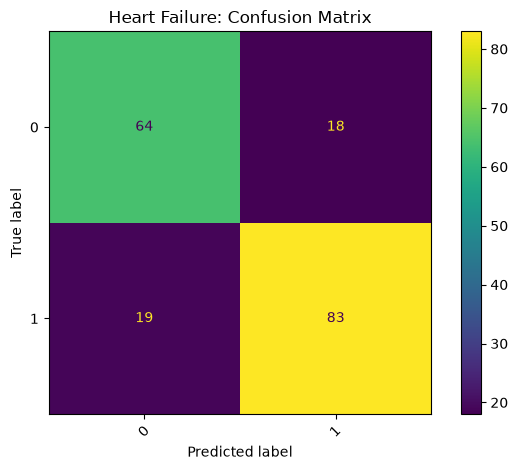

,Dataset,Training rows,Testing rows,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Heart Failure,734,184,0.798913,0.799189,0.798913,0.799027


In [5]:
# Train and evaluate the Decision Tree
heart_model, X_train_heart, X_test_heart, y_train_heart, y_test_heart, heart_results = evaluate_dataset(
    heart_df,
    target_column="HeartDisease",
    dataset_name="Heart Failure"
)

display(pd.DataFrame([heart_results]))

,Dataset,Criterion,Max depth,Accuracy,F1-score (weighted)
0,Heart Failure,gini,2,0.760870,0.760870
1,Heart Failure,gini,3,0.820652,0.821178
2,Heart Failure,gini,5,0.798913,0.799027
3,Heart Failure,gini,10,0.793478,0.793206
4,Heart Failure,gini,None,0.793478,0.793478
5,Heart Failure,entropy,2,0.760870,0.760870
6,Heart Failure,entropy,3,0.820652,0.821178
7,Heart Failure,entropy,5,0.847826,0.847989
8,Heart Failure,entropy,10,0.793478,0.793994
9,Heart Failure,entropy,None,0.782609,0.782322


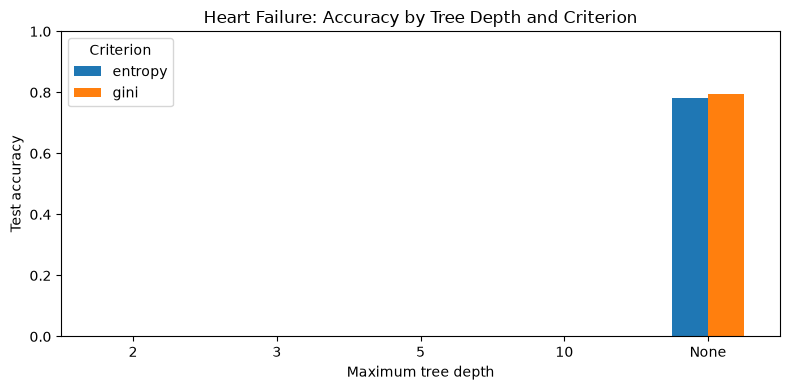

In [6]:
# Compare tree depth and splitting criteria
heart_comparison = compare_depth_and_criterion(
    X_train_heart, X_test_heart, y_train_heart, y_test_heart,
    dataset_name="Heart Failure"
)

# Task 2: Dataset B — Telco Customer Churn

**File:** `Telco-Customer-Churn.csv`  
**Target column:** `Churn`



In [7]:
# Inspect the dataset
display(telco_df.head())
print("Dataset information:")
telco_df.info()
print("\nMissing values:")
display(telco_df.isnull().sum())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Telco Customer Churn — Classification Report
              precision    recall  f1-score   support

          No       0.86      0.86      0.86      1035
         Yes       0.61      0.61      0.61       374

    accuracy                           0.79      1409
   macro avg       0.74      0.74      0.74      1409
weighted avg       0.79      0.79      0.79      1409



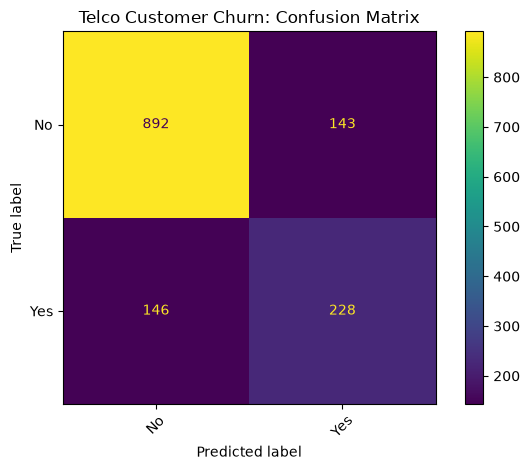

,Dataset,Training rows,Testing rows,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Telco Customer Churn,5634,1409,0.79489,0.794369,0.79489,0.794625


In [8]:
# Train and evaluate the Decision Tree
telco_model, X_train_telco, X_test_telco, y_train_telco, y_test_telco, telco_results = evaluate_dataset(
    telco_df,
    target_column="Churn",
    dataset_name="Telco Customer Churn",
    drop_columns=["customerID"]
)

display(pd.DataFrame([telco_results]))

,Dataset,Criterion,Max depth,Accuracy,F1-score (weighted)
0,Telco Customer Churn,gini,2,0.750887,0.755357
1,Telco Customer Churn,gini,3,0.782115,0.756926
2,Telco Customer Churn,gini,5,0.794890,0.794625
3,Telco Customer Churn,gini,10,0.775018,0.772035
4,Telco Customer Churn,gini,None,0.778566,0.774182
5,Telco Customer Churn,entropy,2,0.750887,0.755357
6,Telco Customer Churn,entropy,3,0.782115,0.756926
7,Telco Customer Churn,entropy,5,0.794890,0.794625
8,Telco Customer Churn,entropy,10,0.783534,0.782098
9,Telco Customer Churn,entropy,None,0.755145,0.754402


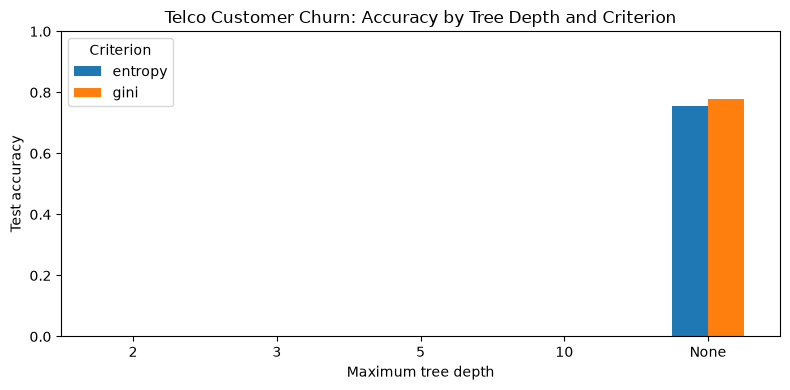

In [9]:
# Compare tree depth and splitting criteria
telco_comparison = compare_depth_and_criterion(
    X_train_telco, X_test_telco, y_train_telco, y_test_telco,
    dataset_name="Telco Customer Churn"
)

# Task 3: Dataset C — Mushroom Classification

**File:** `mushrooms.csv`  
**Target column:** `class`



In [10]:
# Inspect the dataset
display(mushroom_df.head())
print("Dataset information:")
mushroom_df.info()
print("\nMissing values:")
display(mushroom_df.isnull().sum())

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


Mushroom Classification — Classification Report
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



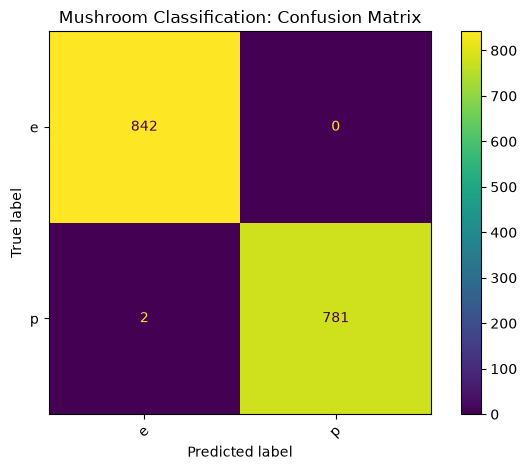

,Dataset,Training rows,Testing rows,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Mushroom Classification,6499,1625,0.998769,0.998772,0.998769,0.998769


In [11]:
# Train and evaluate the Decision Tree
mushroom_model, X_train_mushroom, X_test_mushroom, y_train_mushroom, y_test_mushroom, mushroom_results = evaluate_dataset(
    mushroom_df,
    target_column="class",
    dataset_name="Mushroom Classification"
)

display(pd.DataFrame([mushroom_results]))

,Dataset,Criterion,Max depth,Accuracy,F1-score (weighted)
0,Mushroom Classification,gini,2,0.948923,0.948937
1,Mushroom Classification,gini,3,0.982154,0.982159
2,Mushroom Classification,gini,5,0.998769,0.998769
3,Mushroom Classification,gini,10,1.000000,1.000000
4,Mushroom Classification,gini,None,1.000000,1.000000
5,Mushroom Classification,entropy,2,0.924308,0.923658
6,Mushroom Classification,entropy,3,0.957538,0.957534
7,Mushroom Classification,entropy,5,0.998769,0.998769
8,Mushroom Classification,entropy,10,1.000000,1.000000
9,Mushroom Classification,entropy,None,1.000000,1.000000


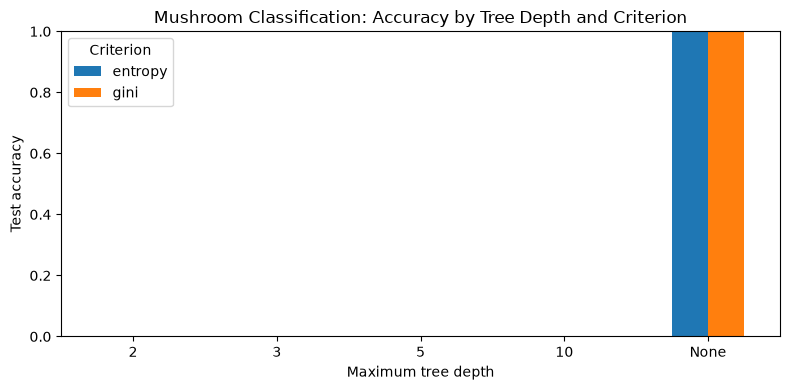

In [12]:
# Compare tree depth and splitting criteria
mushroom_comparison = compare_depth_and_criterion(
    X_train_mushroom, X_test_mushroom, y_train_mushroom, y_test_mushroom,
    dataset_name="Mushroom Classification"
)

# 4. Overall Results and Comparison

The following table combines the baseline Decision Tree results (maximum depth 5, Gini criterion) from all three datasets.

,Dataset,Training rows,Testing rows,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Heart Failure,734,184,0.798913,0.799189,0.798913,0.799027
1,Telco Customer Churn,5634,1409,0.794890,0.794369,0.794890,0.794625
2,Mushroom Classification,6499,1625,0.998769,0.998772,0.998769,0.998769


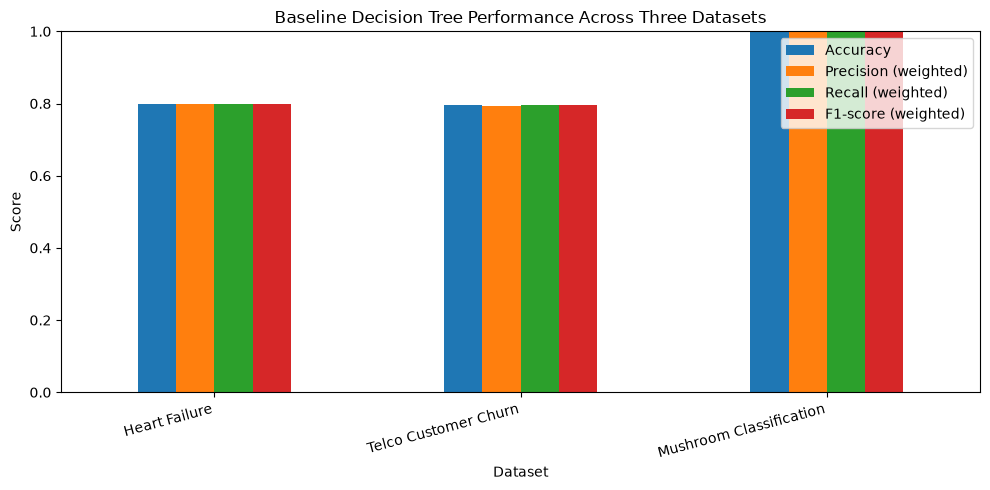

In [13]:
overall_results = pd.DataFrame([
    heart_results,
    telco_results,
    mushroom_results
])

display(overall_results)

overall_results.set_index("Dataset")[
    ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"]
].plot(kind="bar", figsize=(10, 5))
plt.title("Baseline Decision Tree Performance Across Three Datasets")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()